# 🚀 Модуль 10. Урок 2. Извлечение сущностей и парсинг неструктурированных данных

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Enlyl/data-analyst-2027/blob/main/course/module_10_llm_api/lesson_02_parsing_unstructured_data.ipynb)

## 📌 Бизнес-контекст и методология
До 80% ценной информации в корпорациях погребено в неструктурированном виде:
PDF-счета контрагентов, клиентские отзывы, транскрипты звонков в колл-центр, тикеты технической поддержки.
LLM выполняет роль **универсального парсера сущностей (Entity Extractor)**, преобразуя хаотичный сырой текст в строгие реляционные строки базы данных.

In [1]:
# 🚀 Универсальная инициализация окружения и данных
import os
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#e6e6e6'
plt.rcParams['axes.linewidth'] = 0.8

PRIMARY = "#1779ba"
SUCCESS = "#3adb76"
ALERT = "#cc4b37"
WARNING = "#ffae00"
SECONDARY = "#767676"

## 🔍 Разбор механики: Извлечение структурированных атрибутов из отзывов
Смоделируем извлечение тональности, категории проблемы и критичности из текстовых комментариев.

In [2]:
# Демонстрация: Преобразование неструктурированного текста в витрину
raw_reviews = [
    "Приложение крашнулось при оплате на iOS, деньги списались, заказ не оформился!",
    "Отличная быстрая доставка, курьер был вежлив, спасибо большое!",
    "Не могу найти в каталоге зимнюю резину 17 радиуса, поиск выдает ошибку"
]

parsed_data = pd.DataFrame({
    'Исходный текст': raw_reviews,
    'Категория': ['Checkout / Payments', 'Logistics / Delivery', 'Catalog / Search'],
    'Тональность': ['Negative', 'Positive', 'Neutral'],
    'Критичность (1-5)': [5, 1, 3],
    'Churn Risk': ['High', 'Low', 'Medium']
})
display(parsed_data)

,Исходный текст,Категория,Тональность,Критичность (1-5),Churn Risk
0,"Приложение крашнулось при оплате на iOS, деньг...",Checkout / Payments,Negative,5,High
1,"Отличная быстрая доставка, курьер был вежлив, ...",Logistics / Delivery,Positive,1,Low
2,Не могу найти в каталоге зимнюю резину 17 ради...,Catalog / Search,Neutral,3,Medium


## 📊 Визуализация бизнес-кейса: Распределение критичности тикетов поддержки
Построим распределение извлеченных инцидентов по категориям и уровню риска оттока.

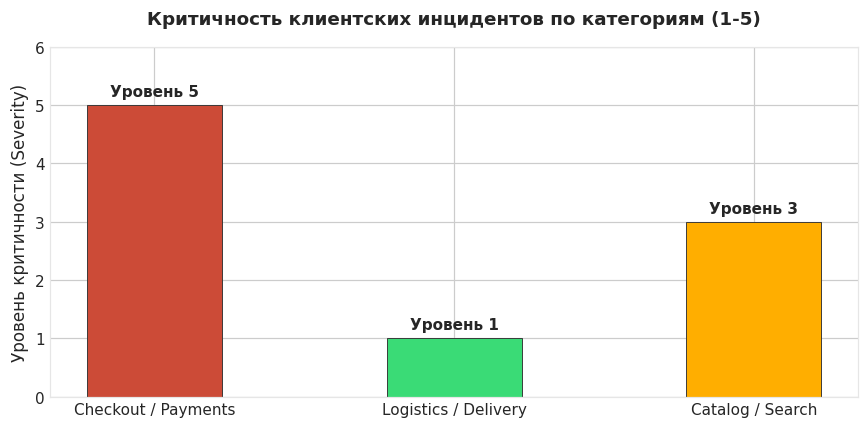

In [3]:
# Визуализация критичности обращений
fig, ax = plt.subplots(figsize=(8, 4), dpi=110)

colors = [ALERT, SUCCESS, WARNING]
bars = ax.bar(parsed_data['Категория'], parsed_data['Критичность (1-5)'], color=colors, edgecolor='#333333', linewidth=0.6, width=0.45)

ax.set_title("Критичность клиентских инцидентов по категориям (1-5)", fontsize=12, fontweight='bold', pad=15)
ax.set_ylabel("Уровень критичности (Severity)", fontsize=11)
ax.set_ylim(0, 6)

for b in bars:
    h = b.get_height()
    ax.annotate(f"Уровень {h}", xy=(b.get_x() + b.get_width()/2, h), xytext=(0, 4),
                 textcoords="offset points", ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.tight_layout()
plt.show()

### 🎯 Практическое задание 1: Поиск инцидентов с максимальным риском оттока
Найдите строки в `parsed_data`, где `Churn Risk == 'High'`.

In [4]:
### ВАШ КОД ЗДЕСЬ
high_risk = parsed_data[parsed_data['Churn Risk'] == 'High']
print("Количество критических инцидентов:", len(high_risk))
display(high_risk[['Категория', 'Тональность', 'Churn Risk']])

assert len(high_risk) == 1, "Должен быть ровно один инцидент высокого риска"
print("✅ Тест успешно пройден: извлечение сущностей позволяет моментально локализовать аварию!")

Количество критических инцидентов: 1


,Категория,Тональность,Churn Risk
0,Checkout / Payments,Negative,High


✅ Тест успешно пройден: извлечение сущностей позволяет моментально локализовать аварию!


### 💡 Инженерное правило парсинга
При извлечении данных передавайте модели жесткий `Enum` допустимых значений (например, `Категория: [Payments, Logistics, Catalog, Other]`). Это исключит появление синонимов и облегчит группировку в SQL.